1. Question and context

What is the historical distribution of Apple's closing prices, and is there any observable visual relationship between trading volume and daily price levels during this period?

2. Data source and imports

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
SOURCE_URL = (
    'https://raw.githubusercontent.com/plotly/'
    'datasets/master/finance-charts-apple.csv'
)

prices = pd.read_csv(SOURCE_URL, parse_dates=['Date'])
prices.head()

,Date,AAPL.Open,AAPL.High,AAPL.Low,AAPL.Close,AAPL.Volume,AAPL.Adjusted,dn,mavg,up,direction
0,2015-02-17,127.489998,128.880005,126.919998,127.830002,63152400,122.905254,106.741052,117.927667,129.114281,Increasing
1,2015-02-18,127.629997,128.779999,127.449997,128.720001,44891700,123.760965,107.842423,118.940333,130.038244,Increasing
2,2015-02-19,128.479996,129.029999,128.330002,128.449997,37362400,123.501363,108.894245,119.889167,130.884089,Decreasing
3,2015-02-20,128.619995,129.500000,128.050003,129.500000,48948400,124.510914,109.785449,120.763500,131.741551,Increasing
4,2015-02-23,130.020004,133.000000,129.660004,133.000000,70974100,127.876074,110.372516,121.720167,133.067817,Increasing


3. Define the analysis table

In [21]:
prices = prices.rename(columns={
    'Date': 'date',
    'AAPL.Open' : 'open',
    'AAPL.Close': 'close',
    'AAPL.Volume': 'volume'
})
prices = prices.sort_values('date').reset_index(drop=True)

analysis = prices[['date', 'open', 'close', 'volume']].copy()
analysis.head(3)

,date,open,close,volume
0,2015-02-17,127.489998,127.830002,63152400
1,2015-02-18,127.629997,128.720001,44891700
2,2015-02-19,128.479996,128.449997,37362400


4. First data audit

In [22]:
print('Shape:', analysis.shape)
print('\nColumns:', analysis.columns.tolist())
print('\nDtypes:\n', analysis.dtypes)

missing = analysis.isna().sum()
audit = pd.DataFrame({
    'missing_count': missing,
    'missing_rate': (missing / len(analysis)).round(4)
})
audit

Shape: (506, 4)

Columns: ['date', 'open', 'close', 'volume']

Dtypes:
 date      datetime64[ns]
open             float64
close            float64
volume             int64
dtype: object


,missing_count,missing_rate
date,0,0.0
open,0,0.0
close,0,0.0
volume,0,0.0


5. Descriptive statistics and returns

In [23]:
summary = analysis['close'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
summary

,close
count,506.000000
mean,112.958340
median,113.025002
std,11.244744
min,90.339996
max,135.509995


6. Returns

In [24]:
analysis['simple_return'] = analysis['close'].pct_change()
analysis['log_return'] = np.log(analysis['close'] / analysis['close'].shift(1))

analysis[['date', 'close', 'simple_return', 'log_return']].head()

,date,close,simple_return,log_return
0,2015-02-17,127.830002,NaN,NaN
1,2015-02-18,128.720001,0.006962,0.006938
2,2015-02-19,128.449997,-0.002098,-0.002100
3,2015-02-20,129.500000,0.008174,0.008141
4,2015-02-23,133.000000,0.027027,0.026668


7. Visualisations

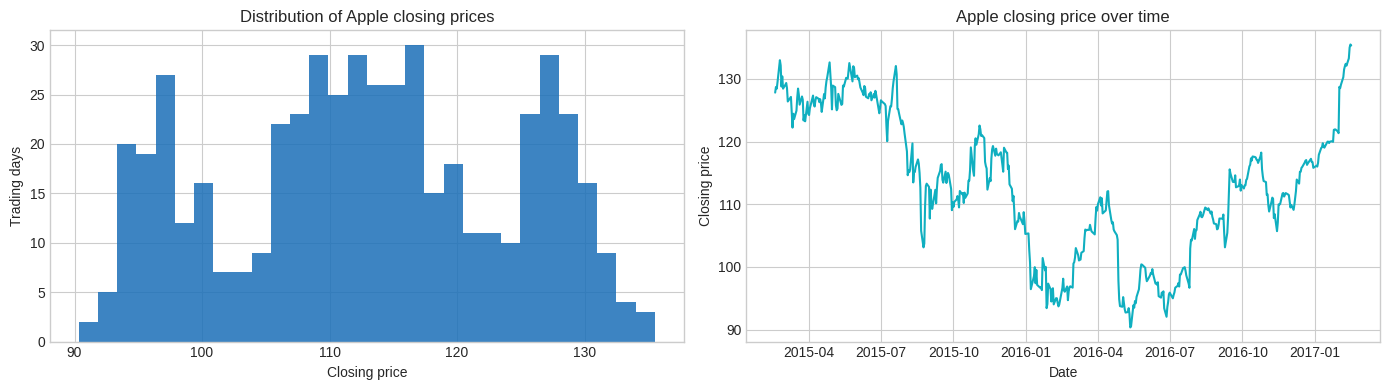

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(analysis['close'].dropna(), bins=30, color='#1B6FB8', alpha=0.85)
axes[0].set_title('Distribution of Apple closing prices')
axes[0].set_xlabel('Closing price')
axes[0].set_ylabel('Trading days')

axes[1].plot(analysis['date'], analysis['close'], color='#10AFC0', linewidth=1.5)
axes[1].set_title('Apple closing price over time')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Closing price')

plt.tight_layout()
plt.show()

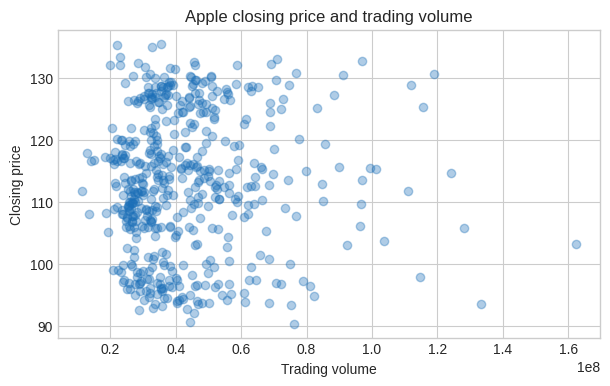

In [26]:
plt.figure(figsize=(7, 4))
plt.scatter(analysis['volume'], analysis['close'], alpha=0.35, color='#1B6FB8')
plt.title('Apple closing price and trading volume')
plt.xlabel('Trading volume')
plt.ylabel('Closing price')
plt.show()

8. Groupped financial summaries

In [27]:
analysis['year'] = analysis['date'].dt.year
annual = (
    analysis.groupby('year')
    .agg(
        average_close=('close', 'mean'),
        median_close=('close', 'median'),
        average_volume=('volume', 'mean'),
        trading_days=('date', 'size')
    )
)
annual.head()

return_summary = analysis['simple_return'].describe()
correlation = analysis[['close', 'volume', 'simple_return']].corr()

print(return_summary)
print('\nCorrelation matrix:')
correlation

count    505.000000
mean       0.000230
std        0.015294
min       -0.065707
25%       -0.006607
50%        0.000000
75%        0.008281
max        0.064963
Name: simple_return, dtype: float64

Correlation matrix:


,close,volume,simple_return
close,1.000000,0.023473,0.085744
volume,0.023473,1.000000,-0.156628
simple_return,0.085744,-0.156628,1.000000


9. Financial interpretation and limitations

The descriptive statistics and visual evidence indicate that Apple's closing price fluctuated around a mean of 113 USD during the examined sample period. The distribution chart reveals that the majority of closing prices clustered between 100 USD and 130 USD. The time-series plot captures the historical trajectory over time, while the scatter plot shows the concentration of trading volume relative to price levels.

These summaries are strictly historical and descriptive. As emphasized in the principles of financial data analysis, these historical charts and basic statistics can't predict future price movements, nor can a scatter plot establish any casual relationship between trading volume and price direction. A historical price chart represents past observations, not an investment return forecast.

